# Notebook 01 — Exploratory Data Analysis
**LADD Benchmark: Litchi Freshness & Formalin Adulteration Detection**

In [1]:
import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.model_selection import train_test_split

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100

# Paths
CSV_PATH = '../data/raw/Litchi Sensor Data.csv'
IMG_ROOT = '../data/raw/images'
PROCESSED_DIR = '../data/processed'
RESULTS_DIR = '../results'
os.makedirs(PROCESSED_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

## 1. Load and Inspect the Sensor Data

In [2]:
df = pd.read_csv(CSV_PATH)
print(f"Dataset shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}")
df.head()

Dataset shape: (3000, 9)
Columns: ['ImageID', 'Moisture', 'Firmness', 'pH', 'TSS', 'Ethanol', 'CO2', 'Formaldehyde', 'Category']


,ImageID,Moisture,Firmness,pH,TSS,Ethanol,CO2,Formaldehyde,Category
0,lithchi_fresh (1),78.841137,2.852363,4.876981,16.641462,0.142193,389.537235,0.049652,Fresh
1,lithchi_fresh (2),79.843266,2.902774,4.902453,18.694582,0.334235,243.754342,0.012332,Fresh
2,lithchi_fresh (3),79.563729,2.327248,4.509003,16.717013,0.317738,265.244101,0.040097,Fresh
3,lithchi_fresh (4),76.569885,3.589619,4.981405,18.775798,0.193496,351.238447,0.035071,Fresh
4,lithchi_fresh (5),79.985255,3.387364,4.863335,16.918393,0.355110,278.751028,0.077284,Fresh


In [3]:
print("Class Distribution:")
print(df['Category'].value_counts())
print(f"\nTotal samples: {len(df)}")

Class Distribution:
Category
Fresh             1000
Rotten            1000
Formalin-Mixed    1000
Name: count, dtype: int64

Total samples: 3000


## 2. Summary Statistics by Category

In [4]:
SENSOR_COLS = ['Moisture', 'Firmness', 'pH', 'TSS', 'Ethanol', 'CO2', 'Formaldehyde']
df.groupby('Category')[SENSOR_COLS].describe().round(2)

Moisture                                                  \
                  count   mean   std    min    25%    50%    75%    max   
Category                                                                  
Formalin-Mixed   1000.0  78.49  2.03  75.01  76.68  78.47  80.33  82.00   
Fresh            1000.0  78.53  2.06  75.03  76.71  78.61  80.31  82.00   
Rotten           1000.0  64.79  2.86  60.00  62.34  64.65  67.08  69.99   

               Firmness        ...      CO2          Formaldehyde              \
                  count  mean  ...      75%      max        count  mean   std   
Category                       ...                                              
Formalin-Mixed   1000.0  3.50  ...   398.85   449.86       1000.0  3.53  0.87   
Fresh            1000.0  3.00  ...   348.02   399.89       1000.0  0.05  0.03   
Rotten           1000.0  0.99  ...  1325.17  1499.19       1000.0  0.10  0.06   

                                             
                 min   25%   50%   75%  max  
Category                                     
Formalin-Mixed  2.01  2.81  3.54  4.31  5.0  
Fresh           0.00  0.03  0.05  0.08  0.1  
Rotten          0.00  0.05  0.10  0.15  0.2  

[3 rows x 56 columns]

In [5]:
print("Mean values by category:")
df.groupby('Category')[SENSOR_COLS].mean().round(3)

Mean values by category:


,Moisture,Firmness,pH,TSS,Ethanol,CO2,Formaldehyde
Category,,,,,,,
Formalin-Mixed,78.488,3.505,4.757,18.037,0.404,351.025,3.535
Fresh,78.525,3.003,4.749,17.957,0.298,298.688,0.050
Rotten,64.787,0.994,3.843,10.068,9.982,1146.552,0.099


## 3. Sensor Feature Distributions by Class

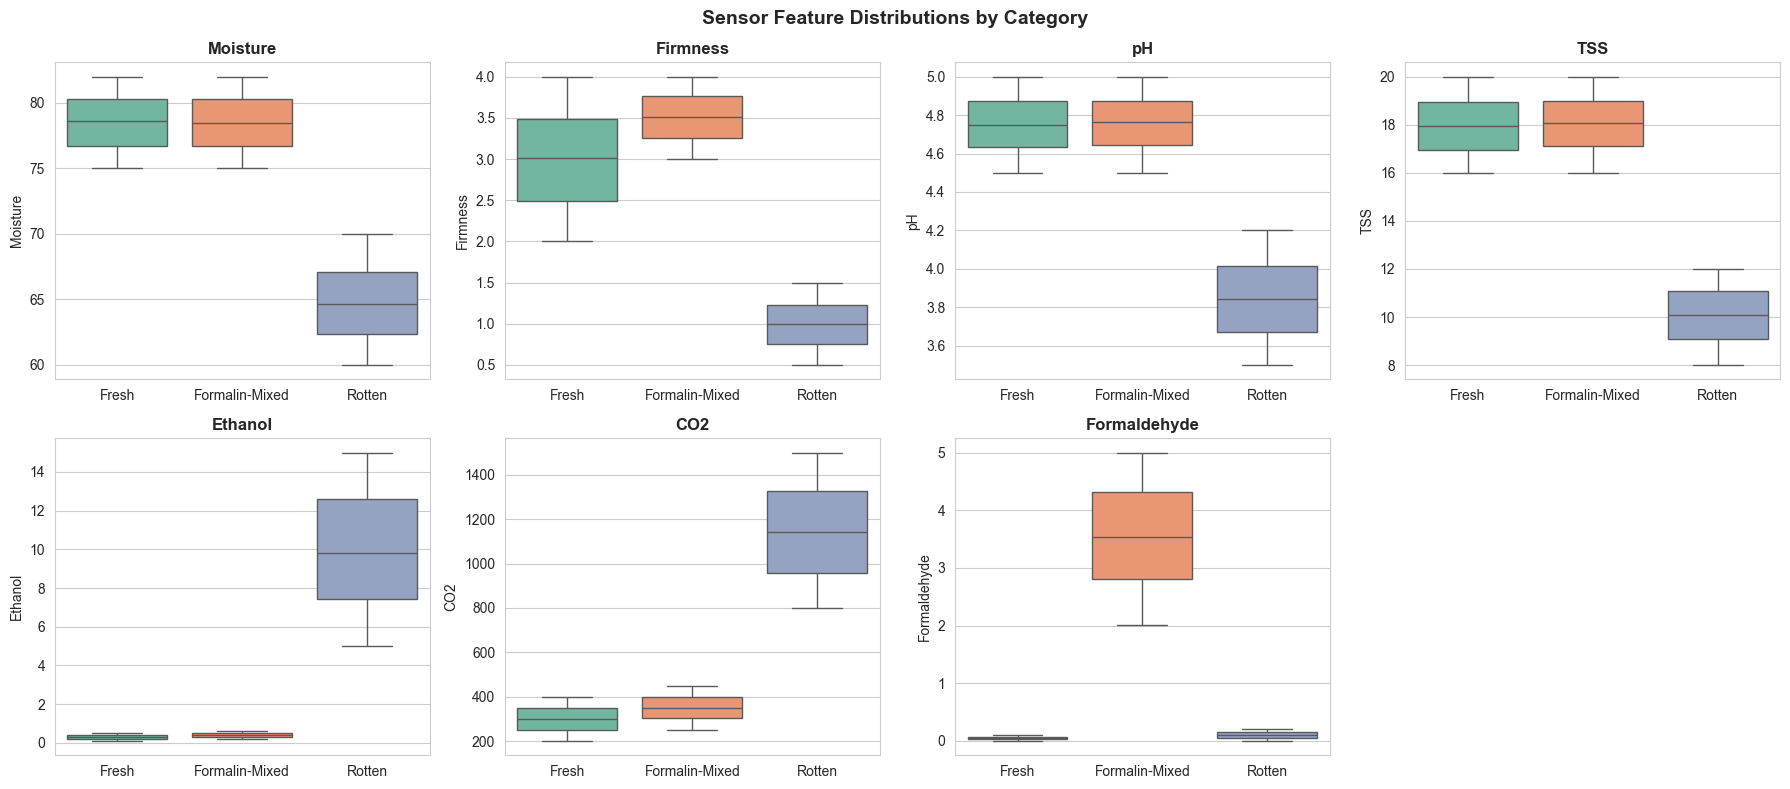

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for i, col in enumerate(SENSOR_COLS):
    sns.boxplot(data=df, x='Category', y=col, ax=axes[i], palette='Set2',
                order=['Fresh', 'Formalin-Mixed', 'Rotten'])
    axes[i].set_title(col, fontsize=12, fontweight='bold')
    axes[i].set_xlabel('')

axes[-1].axis('off')
plt.suptitle('Sensor Feature Distributions by Category', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'eda_boxplots.png'), bbox_inches='tight')
plt.show()

## 4. Correlation Heatmap

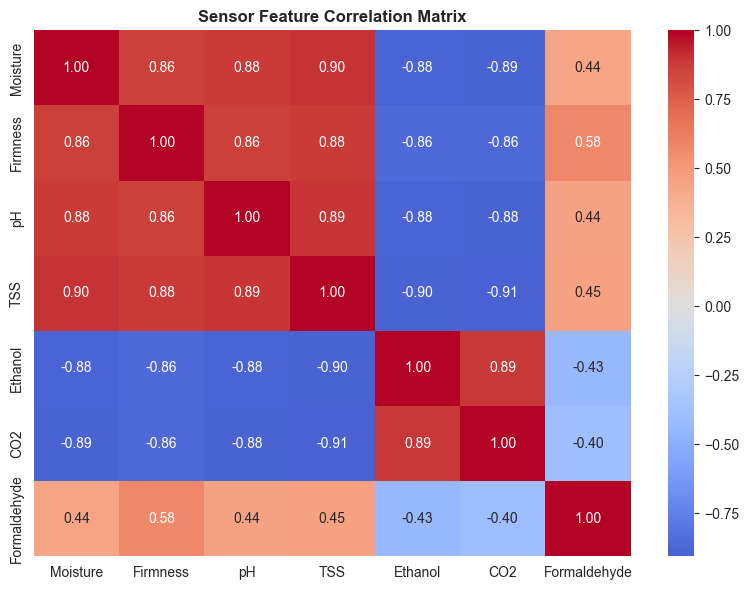

In [7]:
fig, ax = plt.subplots(figsize=(8, 6))
corr = df[SENSOR_COLS].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0, fmt='.2f', ax=ax)
ax.set_title('Sensor Feature Correlation Matrix', fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'eda_correlation.png'), bbox_inches='tight')
plt.show()

## 5. Image Path Resolution

The dataset has naming quirks that must be fixed:
- **Fresh:** File numbers on disk are offset by +999 (CSV says 2, disk has 1001)
- **Rotten:** Numbers 983-1000 in CSV map to .jpeg files numbered 1-18 on disk

In [8]:
def resolve_image_path(img_id, category):
    """Resolve CSV ImageID to the actual file path on disk."""
    folder = 'Formalin' if category == 'Formalin-Mixed' else category
    num = int(re.search(r'\d+', img_id).group())

    if category == 'Formalin-Mixed':
        fname = f"{img_id}.jpg"
    elif category == 'Fresh':
        if num == 1:
            fname = "lithchi_fresh (1).jpg"
        else:
            fname = f"lithchi_fresh ({1000 + num - 1}).jpg"
    elif category == 'Rotten':
        if num > 982:
            fname = f"litchi_rotten ({num - 982}).jpeg"
        else:
            fname = f"litchi_rotten ({num}).jpg"

    path = os.path.join(IMG_ROOT, folder, fname)
    if os.path.exists(path):
        return path
    raise FileNotFoundError(f"Missing: {path}")

In [9]:
df['image_path'] = df.apply(lambda row: resolve_image_path(row['ImageID'], row['Category']), axis=1)
df['label'] = df['Category'].map({'Fresh': 0, 'Formalin-Mixed': 1, 'Rotten': 2})

print(f"All {len(df)} image paths resolved successfully!")
print(f"\nSample paths:")
for cat in ['Fresh', 'Formalin-Mixed', 'Rotten']:
    p = df[df['Category'] == cat]['image_path'].iloc[0]
    print(f"  {cat}: {os.path.basename(p)}")

All 3000 image paths resolved successfully!

Sample paths:
  Fresh: lithchi_fresh (1).jpg
  Formalin-Mixed: litchi_formalin (1).jpg
  Rotten: litchi_rotten (1).jpg


## 6. Sample Images from Each Class

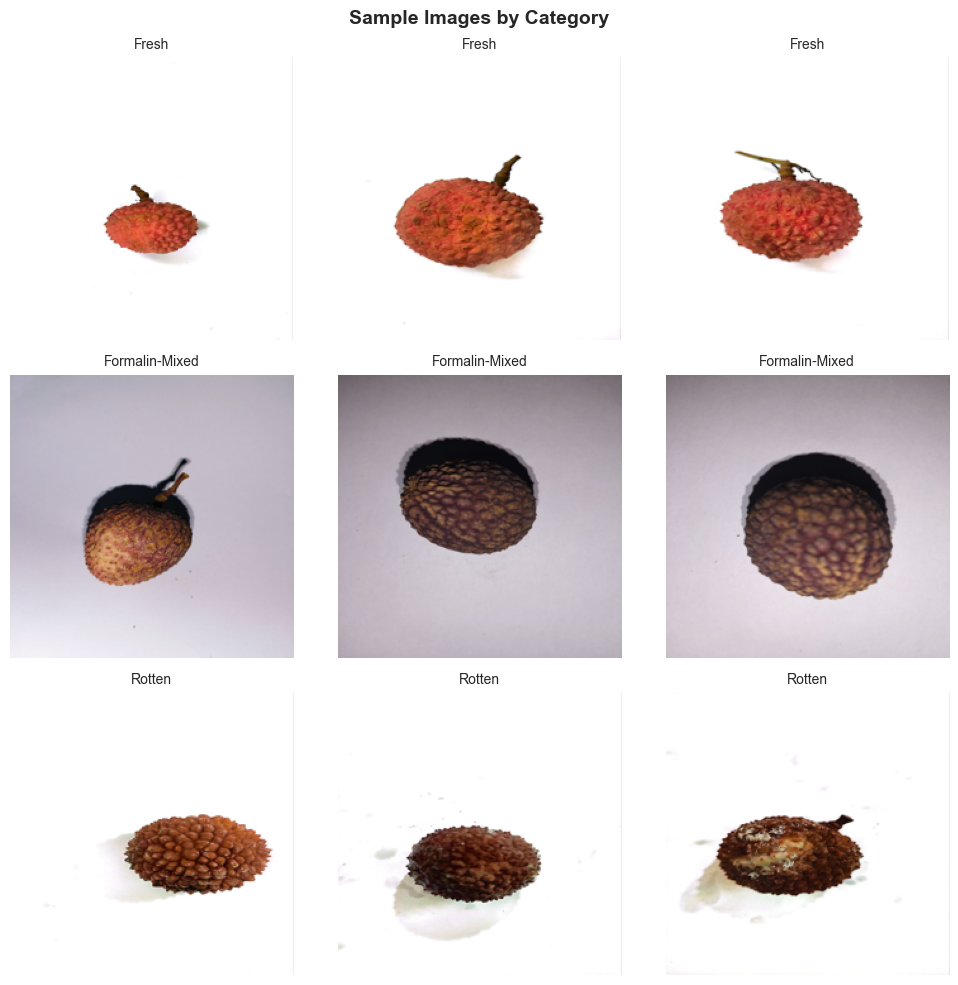

In [10]:
fig, axes = plt.subplots(3, 3, figsize=(10, 10))

for row_idx, cat in enumerate(['Fresh', 'Formalin-Mixed', 'Rotten']):
    subset = df[df['Category'] == cat].sample(3, random_state=42)
    for col_idx, (_, sample) in enumerate(subset.iterrows()):
        img = Image.open(sample['image_path']).resize((224, 224))
        axes[row_idx][col_idx].imshow(img)
        axes[row_idx][col_idx].set_title(cat, fontsize=10)
        axes[row_idx][col_idx].axis('off')

plt.suptitle('Sample Images by Category', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'eda_sample_images.png'), bbox_inches='tight')
plt.show()

## 7. Create Stratified Train / Val / Test Splits

In [11]:
RANDOM_STATE = 42

train_val_df, test_df = train_test_split(
    df, test_size=0.15, random_state=RANDOM_STATE, stratify=df['Category']
)
val_ratio = 0.15 / 0.85
train_df, val_df = train_test_split(
    train_val_df, test_size=val_ratio, random_state=RANDOM_STATE, stratify=train_val_df['Category']
)

print(f"Train: {len(train_df)} samples")
print(f"Val:   {len(val_df)} samples")
print(f"Test:  {len(test_df)} samples")
print(f"\nClass distribution in each split:")
for name, split_df in [('Train', train_df), ('Val', val_df), ('Test', test_df)]:
    counts = split_df['Category'].value_counts().to_dict()
    print(f"  {name}: {counts}")

Train: 2099 samples
Val:   451 samples
Test:  450 samples

Class distribution in each split:
  Train: {'Fresh': 700, 'Formalin-Mixed': 700, 'Rotten': 699}
  Val: {'Rotten': 151, 'Fresh': 150, 'Formalin-Mixed': 150}
  Test: {'Formalin-Mixed': 150, 'Rotten': 150, 'Fresh': 150}


In [12]:
train_df.to_csv(os.path.join(PROCESSED_DIR, "train.csv"), index=False)
val_df.to_csv(os.path.join(PROCESSED_DIR, "val.csv"), index=False)
test_df.to_csv(os.path.join(PROCESSED_DIR, "test.csv"), index=False)

print(f"Saved to {PROCESSED_DIR}/")
print(f"  train.csv: {len(train_df)} rows")
print(f"  val.csv:   {len(val_df)} rows")
print(f"  test.csv:  {len(test_df)} rows")
print(f"\nColumns: {train_df.columns.tolist()}")

Saved to ../data/processed/
  train.csv: 2099 rows
  val.csv:   451 rows
  test.csv:  450 rows

Columns: ['ImageID', 'Moisture', 'Firmness', 'pH', 'TSS', 'Ethanol', 'CO2', 'Formaldehyde', 'Category', 'image_path', 'label']
